# Semana 12 · Pipeline DADA2 → phyloseq
**Bioinformática en el Diagnóstico Molecular**  
**Objetivo:** procesar lecturas FASTQ paired-end 16S y guardar un objeto `phyloseq` para la semana 13.

Dataset: MiSeq SOP (Kozich et al., 2013), empleado en el tutorial oficial DADA2. **Los FASTQ deben estar demultiplexados, sin primers/adaptadores y correctamente emparejados.**

Fuente: https://benjjneb.github.io/dada2/tutorial

## Contexto del experimento: MiSeq SOP

Este conjunto de datos proviene de un estudio de **microbiota intestinal de ratones**, con muestras fecales tomadas longitudinalmente y secuenciadas mediante Illumina MiSeq (amplicón 16S rRNA, región V4). El conjunto empleado en el tutorial DADA2 también contiene una comunidad de referencia (*mock*) que **no debe incluirse en las comparaciones biológicas entre momentos**.

Los identificadores como `F3D0` codifican un ratón (`F3`) y el día de muestreo (`D0`). En el conjunto del tutorial aparecen muestras tempranas (días 0–9) y tardías (días 141–149). Para la **semana 13** construiremos la variable didáctica `Periodo`: **Early = días 0–9** y **Late = días 141–149**. Esta división es una categorización temporal para visualización, **no un tratamiento experimental ni grupos independientes**. Se preservarán también `Raton` y `Dia` para interpretar el diseño longitudinal.

**Referencia de contexto:** Kozich et al. (2013), *Development of a dual-index sequencing strategy and curation pipeline for analyzing amplicon sequence data on the MiSeq Illumina sequencing platform*; tutorial DADA2: https://benjjneb.github.io/dada2/tutorial.html

**Pregunta inicial:** ¿Qué información de diseño experimental podemos recuperar de los identificadores y qué información necesitaríamos verificar con metadatos originales?


## 1 · Preparar el entorno

In [ ]:
if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org")
bioc <- c("dada2", "phyloseq", "DECIPHER", "Biostrings")
missing <- bioc[!vapply(bioc, requireNamespace, logical(1), quietly=TRUE)]
if (length(missing)) BiocManager::install(missing, ask=FALSE, update=FALSE)
cran <- c("ape", "phangorn", "ggplot2")
missing_cran <- cran[!vapply(cran, requireNamespace, logical(1), quietly=TRUE)]
if (length(missing_cran)) install.packages(missing_cran, repos="https://cloud.r-project.org")
library(dada2); library(phyloseq); library(ggplot2)
library(DECIPHER); library(Biostrings); library(ape); library(phangorn)
packageVersion("dada2")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'dada2'

also installing the dependencies ‘GenomicAlignments’, ‘ShortRead’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘fastmatch’, ‘quadprog’


Loading required package: Rcpp

Loading required package: Biostrings

Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘pack

[1] ‘1.40.0’

**Para discutir:** ¿Por qué conviene registrar la versión de DADA2 utilizada?

## 2 · Datos y rutas

In [ ]:
# Crear directorios
dir.create("datos", showWarnings = FALSE)
dir.create("resultados", showWarnings = FALSE)

# Descargar datos de ejemplo de DADA2
url <- "https://mothur.s3.us-east-2.amazonaws.com/wiki/miseqsopdata.zip"
destino <- "datos/miseqsopdata.zip"

download.file(url, destino, mode = "wb")

# Descomprimir
unzip(destino, exdir = "datos")

# Buscar archivos FASTQ de manera recursiva
path <- "datos"

fnFs <- sort(list.files(
  path,
  pattern = "_R1_001\\.fastq(\\.gz)?$",
  full.names = TRUE,
  recursive = TRUE
))

fnRs <- sort(list.files(
  path,
  pattern = "_R2_001\\.fastq(\\.gz)?$",
  full.names = TRUE,
  recursive = TRUE
))

# Extraer identificadores de muestras
get_id <- function(x) {
  sub("_R[12]_001\\.fastq(\\.gz)?$", "", basename(x))
}

stopifnot(
  length(fnFs) > 1,
  length(fnFs) == length(fnRs),
  identical(get_id(fnFs), get_id(fnRs))
)

sample.names <- get_id(fnFs)

stopifnot(!anyDuplicated(sample.names))

data.frame(
  muestra = sample.names,
  forward = basename(fnFs),
  reverse = basename(fnRs)
)

muestra,forward,reverse
<chr>,<chr>,<chr>
F3D0_S188_L001,F3D0_S188_L001_R1_001.fastq,F3D0_S188_L001_R2_001.fastq
F3D1_S189_L001,F3D1_S189_L001_R1_001.fastq,F3D1_S189_L001_R2_001.fastq
F3D141_S207_L001,F3D141_S207_L001_R1_001.fastq,F3D141_S207_L001_R2_001.fastq
F3D142_S208_L001,F3D142_S208_L001_R1_001.fastq,F3D142_S208_L001_R2_001.fastq
F3D143_S209_L001,F3D143_S209_L001_R1_001.fastq,F3D143_S209_L001_R2_001.fastq
F3D144_S210_L001,F3D144_S210_L001_R1_001.fastq,F3D144_S210_L001_R2_001.fastq
F3D145_S211_L001,F3D145_S211_L001_R1_001.fastq,F3D145_S211_L001_R2_001.fastq
F3D146_S212_L001,F3D146_S212_L001_R1_001.fastq,F3D146_S212_L001_R2_001.fastq
F3D147_S213_L001,F3D147_S213_L001_R1_001.fastq,F3D147_S213_L001_R2_001.fastq


**Para discutir:** Comprueba que cada muestra tenga su archivo R1 y R2.

## 3 · Calidad inicial

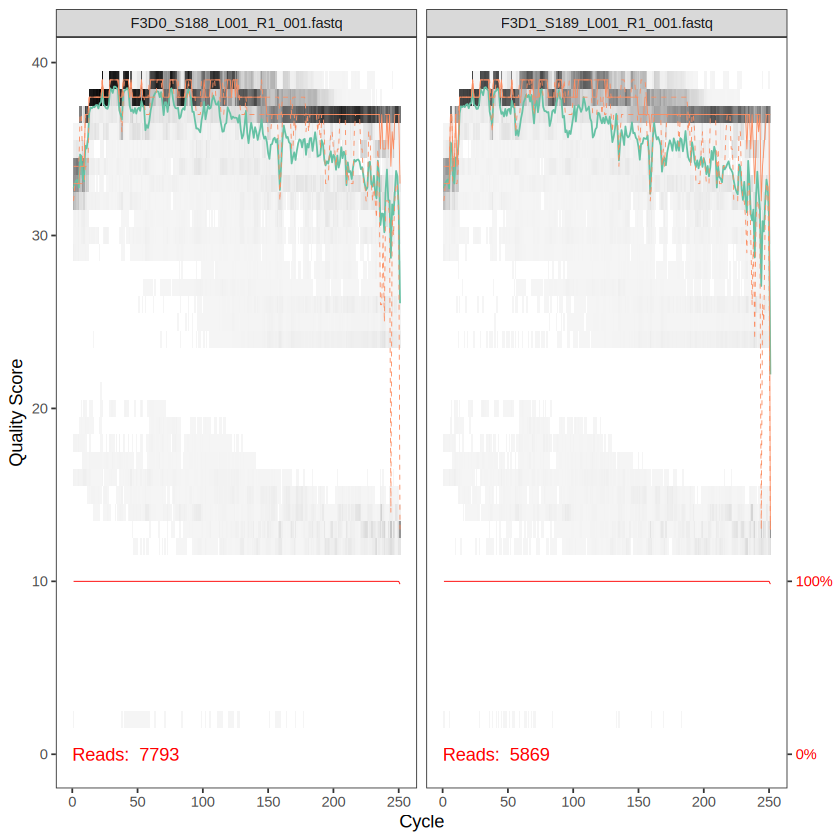

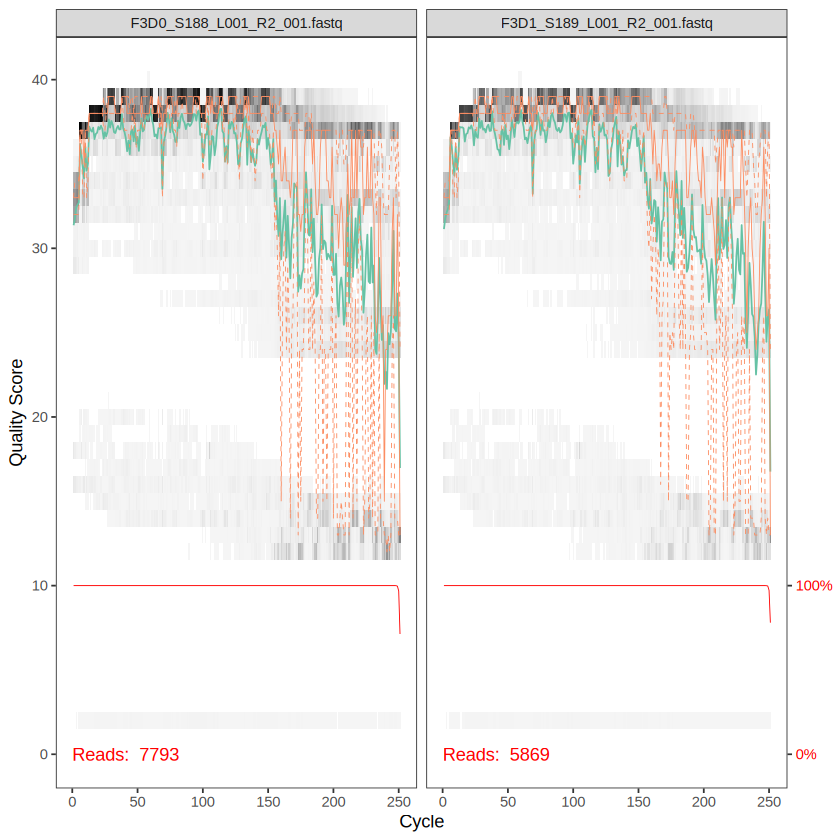

In [ ]:
plotQualityProfile(fnFs[seq_len(min(2,length(fnFs)))])
plotQualityProfile(fnRs[seq_len(min(2,length(fnRs)))])

**Para discutir:** ¿Dónde disminuye la calidad de R2? ¿Qué recortes propondrías?

## 4 · Filtrado y recorte

In [ ]:
dir.create(file.path(path,"filtered"), showWarnings=FALSE)
filtFs <- file.path(path,"filtered",paste0(sample.names,"_F_filt.fastq.gz"))
filtRs <- file.path(path,"filtered",paste0(sample.names,"_R_filt.fastq.gz"))
names(filtFs) <- names(filtRs) <- sample.names
# Parámetros iniciales para el dataset MiSeq SOP; ajustar según perfiles de calidad.
truncF <- 240; truncR <- 160
resultado <- filterAndTrim(fnFs,filtFs,fnRs,filtRs,
  truncLen=c(truncF,truncR),maxN=0,maxEE=c(2,2),truncQ=2,
  rm.phix=TRUE,compress=TRUE,multithread=FALSE)
print(resultado)
stopifnot(all(file.exists(filtFs)),all(file.exists(filtRs)))

                              reads.in reads.out
F3D0_S188_L001_R1_001.fastq       7793      7113
F3D1_S189_L001_R1_001.fastq       5869      5299
F3D141_S207_L001_R1_001.fastq     5958      5463
F3D142_S208_L001_R1_001.fastq     3183      2914
F3D143_S209_L001_R1_001.fastq     3178      2941
F3D144_S210_L001_R1_001.fastq     4827      4312
F3D145_S211_L001_R1_001.fastq     7377      6741
F3D146_S212_L001_R1_001.fastq     5021      4560
F3D147_S213_L001_R1_001.fastq    17070     15637
F3D148_S214_L001_R1_001.fastq    12405     11413
F3D149_S215_L001_R1_001.fastq    13083     12017
F3D150_S216_L001_R1_001.fastq     5509      5032
F3D2_S190_L001_R1_001.fastq      19620     18075
F3D3_S191_L001_R1_001.fastq       6758      6250
F3D5_S193_L001_R1_001.fastq       4448      4052
F3D6_S194_L001_R1_001.fastq       7989      7369
F3D7_S195_L001_R1_001.fastq       5129      4765
F3D8_S196_L001_R1_001.fastq       5294      4871
F3D9_S197_L001_R1_001.fastq       7070      6504
Mock_S280_L001_R1_00

**Para discutir:** La región V4 del ejemplo tiene ~253 pb: ¿hay solapamiento suficiente?

## 5 · Modelo de errores y desreplicación

33514080 total bases in 139642 reads from 20 samples will be used for learning the error rates.
22342720 total bases in 139642 reads from 20 samples will be used for learning the error rates.


Warning message in scale_y_log10():
“log-10 transformation introduced infinite values.”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 164 rows containing missing values or values outside the scale range
(`geom_line()`).”
Dereplicating sequence entries in Fastq file: datos/filtered/F3D0_S188_L001_F_filt.fastq.gz

Encountered 1979 unique sequences from 7113 total sequences read.

Dereplicating sequence entries in Fastq file: datos/filtered/F3D1_S189_L001_F_filt.fastq.gz

Encountered 1639 unique sequences from 5299 total sequences read.

Dereplicating sequence entries in Fastq file: datos/filtered/F3D141_S207_L001_F_filt.fastq.gz

Encountered 1477 unique sequences from 5463 total sequences read.

Dereplicating sequence entries in Fastq file: datos/filtered/F3D142_S208_L001_F_filt.fastq.gz

Encountered 904 unique sequences from 2914 total sequences read.

Dereplicating sequence entries in Fastq fil

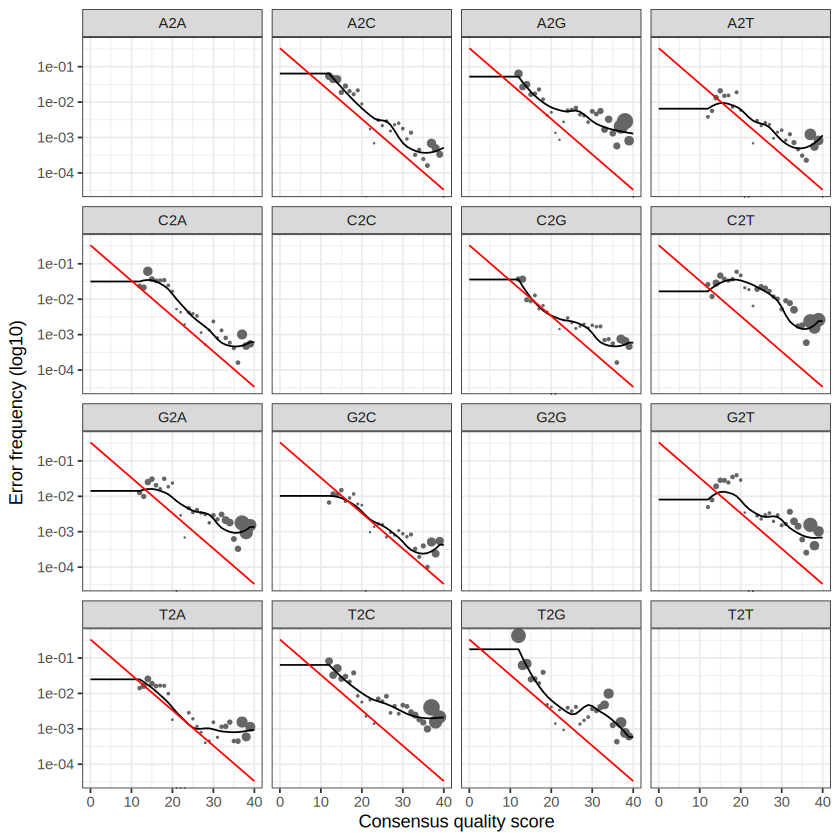

In [ ]:
errF <- learnErrors(filtFs,multithread=FALSE)
errR <- learnErrors(filtRs,multithread=FALSE)
plotErrors(errF,nominalQ=TRUE)
derepFs <- derepFastq(filtFs,verbose=TRUE)
derepRs <- derepFastq(filtRs,verbose=TRUE)
names(derepFs) <- names(derepRs) <- sample.names

**Para discutir:** ¿Qué representan los puntos y las líneas del modelo de errores?

## 6 · Inferencia de ASV y unión paired-end

In [ ]:
dadaFs <- dada(derepFs,err=errF,multithread=FALSE)
dadaRs <- dada(derepRs,err=errR,multithread=FALSE)
mergers <- mergePairs(dadaFs,derepFs,dadaRs,derepRs,verbose=TRUE)
seqtab <- makeSequenceTable(mergers)
print(dim(seqtab))
print(table(nchar(getSequences(seqtab))))

Sample 1 - 7113 reads in 1979 unique sequences.
Sample 2 - 5299 reads in 1639 unique sequences.
Sample 3 - 5463 reads in 1477 unique sequences.
Sample 4 - 2914 reads in 904 unique sequences.
Sample 5 - 2941 reads in 939 unique sequences.
Sample 6 - 4312 reads in 1267 unique sequences.
Sample 7 - 6741 reads in 1756 unique sequences.
Sample 8 - 4560 reads in 1438 unique sequences.
Sample 9 - 15637 reads in 3590 unique sequences.
Sample 10 - 11413 reads in 2762 unique sequences.
Sample 11 - 12017 reads in 3021 unique sequences.
Sample 12 - 5032 reads in 1566 unique sequences.
Sample 13 - 18075 reads in 3707 unique sequences.
Sample 14 - 6250 reads in 1479 unique sequences.
Sample 15 - 4052 reads in 1195 unique sequences.
Sample 16 - 7369 reads in 1832 unique sequences.
Sample 17 - 4765 reads in 1183 unique sequences.
Sample 18 - 4871 reads in 1382 unique sequences.
Sample 19 - 6504 reads in 1709 unique sequences.
Sample 20 - 4314 reads in 897 unique sequences.
Sample 1 - 7113 reads in 166

6540 paired-reads (in 107 unique pairings) successfully merged out of 6891 (in 197 pairings) input.

5028 paired-reads (in 101 unique pairings) successfully merged out of 5190 (in 157 pairings) input.

4986 paired-reads (in 81 unique pairings) successfully merged out of 5267 (in 166 pairings) input.

2595 paired-reads (in 52 unique pairings) successfully merged out of 2754 (in 108 pairings) input.

2553 paired-reads (in 60 unique pairings) successfully merged out of 2785 (in 119 pairings) input.

3646 paired-reads (in 55 unique pairings) successfully merged out of 4109 (in 157 pairings) input.

6079 paired-reads (in 81 unique pairings) successfully merged out of 6514 (in 198 pairings) input.

3968 paired-reads (in 91 unique pairings) successfully merged out of 4388 (in 187 pairings) input.

14233 paired-reads (in 143 unique pairings) successfully merged out of 15355 (in 352 pairings) input.

10528 paired-reads (in 120 unique pairings) successfully merged out of 11165 (in 278 pairings) 

[1]  20 293

251 252 253 254 255 
  1  88 196   6   2 


**Para discutir:** ¿Por qué mergePairs usa derepFs y derepRs, no las rutas de los FASTQ filtrados?

## 7 · Eliminar quimeras y seguimiento

In [ ]:
seqtab.nochim <- removeBimeraDenovo(seqtab,method="consensus",multithread=FALSE,verbose=TRUE)
getN <- function(x) sum(getUniques(x))
track <- cbind(resultado,
  denoisedF=sapply(dadaFs,getN),denoisedR=sapply(dadaRs,getN),
  merged=sapply(mergers,getN),nonchim=rowSums(seqtab.nochim))
rownames(track) <- sample.names
print(track)
write.csv(track,"resultados/seguimiento_lecturas.csv")
cat("ASV sin quimeras:",ncol(seqtab.nochim),"\n")

Identified 61 bimeras out of 293 input sequences.



                 reads.in reads.out denoisedF denoisedR merged nonchim
F3D0_S188_L001       7793      7113      6976      6979   6540    6528
F3D1_S189_L001       5869      5299      5227      5239   5028    5017
F3D141_S207_L001     5958      5463      5331      5357   4986    4863
F3D142_S208_L001     3183      2914      2799      2830   2595    2521
F3D143_S209_L001     3178      2941      2822      2868   2553    2519
F3D144_S210_L001     4827      4312      4151      4228   3646    3507
F3D145_S211_L001     7377      6741      6592      6627   6079    5820
F3D146_S212_L001     5021      4560      4450      4470   3968    3879
F3D147_S213_L001    17070     15637     15433     15506  14233   13006
F3D148_S214_L001    12405     11413     11250     11268  10528    9935
F3D149_S215_L001    13083     12017     11857     11898  11154   10653
F3D150_S216_L001     5509      5032      4880      4925   4349    4240
F3D2_S190_L001      19620     18075     17907     17939  17431   16835
F3D3_S

**Para discutir:** ¿En qué etapa se pierden más lecturas? Propón una explicación.

## 8 · Taxonomía SILVA

In [ ]:
# 1. Crear carpeta
dir.create("referencias", showWarnings = FALSE)

# 2. Definir archivos SILVA 138.1
ref <- "referencias/silva_nr99_v138.1_train_set.fa.gz"

ref_species <- "referencias/silva_species_assignment_v138.1.fa.gz"

# 3. Enlaces oficiales
url_ref <- paste0(
  "https://zenodo.org/records/4587955/files/",
  "silva_nr99_v138.1_train_set.fa.gz?download=1"
)

url_species <- paste0(
  "https://zenodo.org/records/4587955/files/",
  "silva_species_assignment_v138.1.fa.gz?download=1"
)

# 4. Descargar si todavía no existen
options(timeout = 1800)

descargar_ref <- function(url, destino) {
  if (!file.exists(destino) || file.size(destino) == 0) {
    download.file(url, destino, mode = "wb", quiet = FALSE)
  }
  stopifnot(file.exists(destino), file.size(destino) > 0)
}

descargar_ref(url_ref, ref)
descargar_ref(url_species, ref_species)

# 5. Clasificación taxonómica
taxa <- assignTaxonomy(
  seqtab.nochim,
  refFasta = ref,
  multithread = FALSE
)

# 6. Asignación de especies
taxa <- addSpecies(
  taxa,
  refFasta = ref_species,
  verbose = TRUE
)

# 7. Revisar resultados
head(taxa)

16 out of 232 were assigned to the species level.
Of which 15 had genera consistent with the input table.

,Kingdom,Phylum,Class,Order,Family,Genus,Species
TACGGAGGATGCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGTGCGCAGGCGGAAGATCAAGTCAGCGGTAAAATTGAGAGGCTCAACCTCTTCGAGCCGTTGAAACTGGTTTTCTTGAGTGAGCGAGAAGTATGCGGAATGCGTGGTGTAGCGGTGAAATGCATAGATATCACGCAGAACTCCGATTGCGAAGGCAGCATACCGGCGCTCAACTGACGCTCATGCACGAAAGTGTGGGTATCGAACAGG,Bacteria,Bacteroidota,Bacteroidia,Bacteroidales,Muribaculaceae,NA,NA
TACGGAGGATGCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGTGCGCAGGCGGACTCTCAAGTCAGCGGTCAAATCGCGGGGCTCAACCCCGTTCCGCCGTTGAAACTGGGAGCCTTGAGTGCGCGAGAAGTAGGCGGAATGCGTGGTGTAGCGGTGAAATGCATAGATATCACGCAGAACTCCGATTGCGAAGGCAGCCTACCGGCGCGCAACTGACGCTCATGCACGAAAGCGTGGGTATCGAACAGG,Bacteria,Bacteroidota,Bacteroidia,Bacteroidales,Muribaculaceae,NA,NA
TACGGAGGATGCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGTGCGTAGGCGGGCTGTTAAGTCAGCGGTCAAATGTCGGGGCTCAACCCCGGCCTGCCGTTGAAACTGGCGGCCTCGAGTGGGCGAGAAGTATGCGGAATGCGTGGTGTAGCGGTGAAATGCATAGATATCACGCAGAACTCCGATTGCGAAGGCAGCATACCGGCGCCCGACTGACGCTGAGGCACGAAAGCGTGGGTATCGAACAGG,Bacteria,Bacteroidota,Bacteroidia,Bacteroidales,Muribaculaceae,NA,NA
TACGGAGGATGCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGTGCGTAGGCGGGCTTTTAAGTCAGCGGTAAAAATTCGGGGCTCAACCCCGTCCGGCCGTTGAAACTGGGGGCCTTGAGTGGGCGAGAAGAAGGCGGAATGCGTGGTGTAGCGGTGAAATGCATAGATATCACGCAGAACCCCGATTGCGAAGGCAGCCTTCCGGCGCCCTACTGACGCTGAGGCACGAAAGTGCGGGGATCGAACAGG,Bacteria,Bacteroidota,Bacteroidia,Bacteroidales,Muribaculaceae,NA,NA
TACGGAGGATCCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGAGCGTAGGTGGATTGTTAAGTCAGTTGTGAAAGTTTGCGGCTCAACCGTAAAATTGCAGTTGAAACTGGCAGTCTTGAGTACAGTAGAGGTGGGCGGAATTCGTGGTGTAGCGGTGAAATGCTTAGATATCACGAAGAACTCCGATTGCGAAGGCAGCTCACTGGACTGCAACTGACACTGATGCTCGAAAGTGTGGGTATCAAACAGG,Bacteria,Bacteroidota,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,NA
TACGGAGGATGCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGTGCGTAGGCGGCCTGCCAAGTCAGCGGTAAAATTGCGGGGCTCAACCCCGTACAGCCGTTGAAACTGCCGGGCTCGAGTGGGCGAGAAGTATGCGGAATGCGTGGTGTAGCGGTGAAATGCATAGATATCACGCAGAACCCCGATTGCGAAGGCAGCATACCGGCGCCCTACTGACGCTGAGGCACGAAAGTGCGGGGATCAAACAGG,Bacteria,Bacteroidota,Bacteroidia,Bacteroidales,Muribaculaceae,NA,NA


**Para discutir:** ¿Por qué algunas ASV no se clasifican hasta género o especie?

## 9 · Metadatos

**Preparación para la semana 13:** revisa que `Periodo` tenga las categorías `Early` y `Late`, y que `Raton` identifique al individuo. Las muestras `Mock` se mantienen para control de calidad, pero se excluirán de gráficos comparativos de microbiota fecal.


In [ ]:
# Metadatos derivados de los identificadores del conjunto MiSeq SOP.
# La división Early/Late se usa con fines docentes, no representa tratamientos.
es_mock <- grepl("mock", sample.names, ignore.case = TRUE)
extraer_dia <- function(id) {
  x <- regmatches(id, regexpr("D[0-9]+", id))
  if (length(x) == 0 || identical(x, "")) return(NA_integer_)
  as.integer(sub("^D", "", x))
}
extraer_raton <- function(id) {
  if (grepl("^F[0-9]+D[0-9]+", id)) sub("^(F[0-9]+)D.*$", "\\1", id)
  else NA_character_
}
dia <- vapply(sample.names, extraer_dia, integer(1))
raton <- vapply(sample.names, extraer_raton, character(1))
dia[es_mock] <- NA_integer_
raton[es_mock] <- NA_character_
periodo <- ifelse(es_mock, "Mock",
           ifelse(!is.na(dia) & dia <= 9, "Early",
           ifelse(!is.na(dia) & dia >= 141 & dia <= 149, "Late", NA_character_)))
metadata <- data.frame(
  SampleID = sample.names,
  Tipo = ifelse(es_mock, "Mock", "Raton"),
  Raton = raton,
  Dia = dia,
  Periodo = factor(periodo, levels = c("Early", "Late", "Mock")),
  row.names = sample.names,
  stringsAsFactors = FALSE
)
print(metadata)
print(table(metadata$Periodo, useNA = "ifany"))
stopifnot(identical(rownames(metadata), rownames(seqtab.nochim)))
stopifnot(!any(is.na(metadata$Periodo[metadata$Tipo == "Raton"])))


Warning message in data.frame(SampleID = sample.names, Tipo = ifelse(grepl("Mock", :
“NAs introduced by coercion”


                         SampleID  Tipo Dia
F3D0_S188_L001     F3D0_S188_L001 Ratón   0
F3D1_S189_L001     F3D1_S189_L001 Ratón   1
F3D141_S207_L001 F3D141_S207_L001 Ratón 141
F3D142_S208_L001 F3D142_S208_L001 Ratón 142
F3D143_S209_L001 F3D143_S209_L001 Ratón 143
F3D144_S210_L001 F3D144_S210_L001 Ratón 144
F3D145_S211_L001 F3D145_S211_L001 Ratón 145
F3D146_S212_L001 F3D146_S212_L001 Ratón 146
F3D147_S213_L001 F3D147_S213_L001 Ratón 147
F3D148_S214_L001 F3D148_S214_L001 Ratón 148
F3D149_S215_L001 F3D149_S215_L001 Ratón 149
F3D150_S216_L001 F3D150_S216_L001 Ratón 150
F3D2_S190_L001     F3D2_S190_L001 Ratón   2
F3D3_S191_L001     F3D3_S191_L001 Ratón   3
F3D5_S193_L001     F3D5_S193_L001 Ratón   5
F3D6_S194_L001     F3D6_S194_L001 Ratón   6
F3D7_S195_L001     F3D7_S195_L001 Ratón   7
F3D8_S196_L001     F3D8_S196_L001 Ratón   8
F3D9_S197_L001     F3D9_S197_L001 Ratón   9
Mock_S280_L001     Mock_S280_L001  Mock  NA


**Para discutir:** ¿Qué variables provienen del identificador de la muestra? ¿Qué significa `Early` frente a `Late`? ¿Por qué las muestras del mismo ratón no deben tratarse como réplicas independientes?


## 10 · Árbol filogenético (opcional, puede tardar)

In [ ]:
# Para conjuntos pequeños de ASV; si el tiempo es limitado,
# construir phyloseq sin árbol y agregarlo después.
construir_arbol <- FALSE
arbol <- NULL
if (construir_arbol) {
  seqs <- getSequences(seqtab.nochim)
  names(seqs) <- seqs
  alineamiento <- AlignSeqs(DNAStringSet(seqs),anchor=NA,verbose=FALSE)
  phang.align <- phyDat(as(alineamiento,"matrix"),type="DNA")
  dm <- dist.ml(phang.align)
  treeNJ <- NJ(dm)
  fit <- pml(treeNJ,data=phang.align)
  fitGTR <- optim.pml(fit,model="GTR",optInv=TRUE,optGamma=TRUE,
                      rearrangement="stochastic",control=pml.control(trace=0))
  arbol <- fitGTR$tree
}

**Para discutir:** ¿Qué análisis de la semana 13 necesitarán árbol filogenético?

## 11 · Construcción y validación phyloseq

In [ ]:
ps <- phyloseq(otu_table(seqtab.nochim,taxa_are_rows=FALSE),
               tax_table(taxa),sample_data(metadata))
if (!is.null(arbol)) ps <- merge_phyloseq(ps,phy_tree(arbol))
print(ps)
stopifnot(nsamples(ps)==nrow(seqtab.nochim),ntaxa(ps)==ncol(seqtab.nochim))
stopifnot(setequal(sample_names(ps),rownames(metadata)))
print(sample_variables(ps)); print(rank_names(ps))

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 232 taxa and 20 samples ]
sample_data() Sample Data:       [ 20 samples by 3 sample variables ]
tax_table()   Taxonomy Table:    [ 232 taxa by 7 taxonomic ranks ]
[1] "SampleID" "Tipo"     "Dia"     
[1] "Kingdom" "Phylum"  "Class"   "Order"   "Family"  "Genus"   "Species"


**Para discutir:** Explica qué representa cada componente del objeto phyloseq.

## 12 · Exportar para la semana 13

In [ ]:
dir.create("resultados", showWarnings = FALSE)
saveRDS(ps, "resultados/Phyloseq_practico.rds")
write.csv(as.data.frame(seqtab.nochim), "resultados/tabla_ASV.csv")
write.csv(as.data.frame(taxa), "resultados/taxonomia.csv")
write.csv(metadata, "resultados/metadata.csv")
stopifnot(inherits(readRDS("resultados/Phyloseq_practico.rds"), "phyloseq"))
print(list.files("resultados"))
# Comprimir todo para descargarlo desde el panel Archivos de Colab.
# En un entorno Colab con celda Python, se puede usar:
# from google.colab import files
# files.download("resultados_semana12.zip")
utils::zip("resultados_semana12.zip", files = list.files("resultados", full.names = TRUE))


[1] "metadata.csv"             "microbiota_semana12.rds" 
[3] "Phyloseq_practico.rds"    "seguimiento_lecturas.csv"
[5] "tabla_ASV.csv"            "taxonomia.csv"

**Para discutir:** Entrega: notebook ejecutado, seguimiento de lecturas y archivo .rds.